# FPV-MonoSingle vs. the ortho arms on a toy world

**Goal:** show that orthographic views (Top, Side, Rear) make a first-person (FPV) world model better. Clean frames are context. Noisy frames are what the model denoises and is scored on.

**Game-engine rule:** at inference the model only gets its **own outputs** ($\hat x_0$) back, never real frames. Every number below comes from an autoregressive rollout where each step's context is the previous step's prediction.

This notebook imports `train_ortho_trajectory_step` and `predict_next_view_latents` straight from `new_train_ortho_wan.py` (and the Ortho-Project functions from `train_ortho_project.py`), so it exercises the training scripts' code. A ~3M-parameter `ToyDiT` stands in for Wan (same call signature), and a toy world stands in for the games. Everything runs in about 10 minutes on a GPU.

### The arms

Frame numbers follow the full layout, so a view always has the same number.

**FPV-MonoSingle**: the baseline, the usual diffusion world model. Not an `--arm` in the script; it's the reference here.
```
frame:     3   |   7
          FPV  |  FPV
loss:          |  yes
```

**FPV-BaseSingle** (`--arm fpv_base`): sees FPV, also predicts the ortho views. Only FPV is fed back.
```
frame:     3   |   4      5      6      7
          FPV  |  Top    Side   Rear   FPV
loss:          |   yes    yes    yes    yes
```

**Ortho-Base** (`--arm ortho_base`): sees all four views.
```
frame:     0     1     2     3   |   4      5      6      7
         Top   Side  Rear  FPV   |  Top    Side   Rear   FPV
         ---- views_t (clean) -- | ---- views_{t+1} (noisy at tau) ----
loss:                            |   yes    yes    yes    yes
```

**Ortho-Project** (`train_ortho_project.py`): Ortho-Base plus a sketch of the next FPV. See section 5b.

In [1]:
import math, time, warnings
from types import SimpleNamespace

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
import new_train_ortho_wan as wm   # the training script: arms, trajectory step, sampler

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

VIEW_NAMES = ["Top", "Side", "Rear", "FPV"]   # same order as the script: FPV is the last view
V = 4                                         # views per timestep
C, H, W = 4, 4, 4                             # toy latent size (Wan: C=16, h=w=12 for 96x96 frames)
print("device:", device)

device: cuda


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## 1. The toy world: laps around a circuit

* **The circuit** is a ring of 8 segments, random for each episode. Each segment is one row of every ortho view: $C$ channels × 3 views × $W$ pixels.
* **The ortho views** show a window of $H = 4$ consecutive segments. Every step the player drives one segment forward: the rows scroll up and a new segment enters at the bottom. The world has no other randomness.
* **The camera** $c_t$: $C$ channels per pixel that **only FPV sees** (e.g. yaw/pitch). It changes slowly: $c_{t+1} = 0.9\,c_t + \sqrt{0.19}\,w$.
* **FPV** renders both: $f_t = (R\,o_t + c_t)/\sqrt2$, with $R$ a fixed per-pixel $12\to4$ projection of the three ortho views.

The segment entering at $t+1$ isn't in any view at $t$. Every arm here sees only step $t$, so it has to guess that segment.

The table prints the error of the best linear predictor from each context, i.e. how much each context knows about the next frame. The world is linear-Gaussian, so this is exact.

In [2]:
RING = 8                                      # segments around the circuit; the window shows H = 4 of them
_g = torch.Generator().manual_seed(1234)
RENDER = (torch.randn(C, 3 * C, generator=_g) / math.sqrt(3 * C)).to(device)  # fixed "renderer" R

def layout_to_fpv(o):
    # (B, C, 3, H, W) -> (B, C, 1, H, W): R o, the part of FPV the ortho views explain
    px = o.permute(0, 3, 4, 2, 1).reshape(o.shape[0], H, W, 3 * C) @ RENDER.T
    return px.permute(0, 3, 1, 2).unsqueeze(2)

def init_state(b):
    # (circuit (B, RING, C, 3, W), position (B,), camera (B, C, 1, H, W))
    return (torch.randn(b, RING, C, 3, W, device=device), torch.randint(0, RING, (b,), device=device),
            torch.randn(b, C, 1, H, W, device=device))

def world_step(state):
    ring, pos, cam = state
    return ring, (pos + 1) % RING, 0.9 * cam + math.sqrt(0.19) * torch.randn_like(cam)

def render(state):
    # World state -> the 4 views (B, C, 4, H, W), order Top, Side, Rear, FPV
    ring, pos, cam = state
    rows = (pos[:, None] + torch.arange(H, device=device)) % RING                # the H segments in view
    o = ring[torch.arange(len(pos), device=device)[:, None], rows].permute(0, 2, 3, 1, 4)  # (B, C, 3, H, W)
    return torch.cat([o, (layout_to_fpv(o) + cam) / math.sqrt(2)], dim=2)

def trajectory(b, steps):
    # Rendered views at steps 0..steps of one lap segment per sample
    state = init_state(b)
    views = [render(state)]
    for _ in range(steps):
        state = world_step(state)
        views.append(render(state))
    return views

def cond_var(y, x):
    # Residual variance of the best linear predictor of y from x (exact: the toy is linear-Gaussian)
    X = torch.cat([x.flatten(1), torch.ones(len(x), 1, device=x.device)], dim=1).cpu()
    Y = y.flatten(1).cpu()
    return (Y - X @ torch.linalg.lstsq(X, Y, driver="gelsd").solution).var().item()   # SVD: handles repeated frames

traj = trajectory(20000, 1)
fpv_next, top_next = traj[1][:, :, 3], traj[1][:, :, 0]
print("What each context knows about the next frame: best linear predictor error (lower = more informative, 1.0 = nothing)")
for name, target, ctx, who in [
    ("FPV", fpv_next, traj[0][:, :, 3:], "FPV-MonoSingle / FPV-BaseSingle"),
    ("FPV", fpv_next, traj[0],           "Ortho-Base"),
    ("Top", top_next, traj[0],           "Ortho-Base"),
]:
    print(f"  err({name}_t+1 | {who:31s}) = {cond_var(target, ctx):.3f}")

What each context knows about the next frame: best linear predictor error (lower = more informative, 1.0 = nothing)
  err(FPV_t+1 | FPV-MonoSingle / FPV-BaseSingle) = 0.468
  err(FPV_t+1 | Ortho-Base                     ) = 0.187
  err(Top_t+1 | Ortho-Base                     ) = 0.246


## 2. A stand-in for Wan

`ToyDiT` has the same call as `WanTransformer3DModel`: `transformer(hidden_states=(B, C, F, H, W), timestep=(B,), encoder_hidden_states=...).sample`, plus the `.dtype` the script reads. Each frame is one token. A learned frame embedding plays the role of the 3D RoPE. The prompt is ignored: in the toy the player always drives forward, so there is no action to condition on.

In [3]:
class ToyDiT(nn.Module):
    def __init__(self, max_frames=9, d=256, layers=4):   # 9 = Ortho-Project's 4 context + sketch + 4 targets
        super().__init__()
        self.inp = nn.Linear(C * H * W, d)
        self.pos = nn.Parameter(0.02 * torch.randn(max_frames, d))  # frame position, stands in for Wan's RoPE
        self.t_emb = nn.Sequential(nn.Linear(1, d), nn.SiLU(), nn.Linear(d, d))
        layer = nn.TransformerEncoderLayer(d, nhead=4, dim_feedforward=4 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.out = nn.Linear(d, C * H * W)

    @property
    def dtype(self):
        return next(self.parameters()).dtype

    def forward(self, hidden_states, timestep, encoder_hidden_states=None):
        b, c, f, h, w = hidden_states.shape
        x = hidden_states.permute(0, 2, 1, 3, 4).reshape(b, f, c * h * w)
        x = self.inp(x) + self.pos[:f] + self.t_emb((timestep.float() / 1000.0).view(b, 1, 1))  # ONE timestep per sample
        x = self.out(self.blocks(x))
        return SimpleNamespace(sample=x.view(b, f, c, h, w).permute(0, 2, 1, 3, 4))

print(f"ToyDiT params: {sum(p.numel() for p in ToyDiT().parameters()) / 1e6:.2f}M")

ToyDiT params: 3.26M


## 3. Training the three arms with the script's trajectory step

Each arm is the script's arm definition: context views at $t$, target views at $t+1$. One update is one trained step of the script's `train_ortho_trajectory_step`.

All arms get the same budget: 4000 updates, batch 256, the same seed. `teacher_forcing_prob=0`, so contexts are ground truth during training; the rollouts in section 4 are where generated frames go back in.

Don't compare training losses across arms. They score different targets under different conditioning.

In [4]:
ARMS = {
    "FPV-MonoSingle": {"context": (3,), "targets": (3,)},
    "FPV-BaseSingle": wm.ARMS["fpv_base"],
    "Ortho-Base":     wm.ARMS["ortho_base"],
}

def arm_setup(arm):
    ctx, tgt = arm["context"], arm["targets"]
    return ctx, tgt, [tgt.index(i) for i in ctx]

def train_arm(arm, steps=4000, batch_size=256, lr=3e-4, seed=0):
    ctx, tgt, ctx_in_tgt = arm_setup(arm)
    torch.manual_seed(seed)
    model = ToyDiT().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr * 0.1)
    for _ in range(steps):
        views = trajectory(batch_size, 1)
        opt.zero_grad(set_to_none=True)
        wm.train_ortho_trajectory_step(model, views[0][:, :, list(ctx)], [views[1][:, :, list(tgt)]], [None], ctx_in_tgt,
                                       teacher_forcing_prob=0.0)   # calls backward itself
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step(); sched.step()
    return model.eval()

models = {}
for name, arm in ARMS.items():
    t0 = time.time()
    models[name] = train_arm(arm)
    print(f"trained {name:15s} in {time.time() - t0:.0f}s")

trained FPV-MonoSingle  in 40s


trained FPV-BaseSingle  in 45s


trained Ortho-Base      in 57s


## 4. Rollouts: the game engine

This mirrors the script's `autoregressive_rollout`. Start from real views at step 0, then each step:
1. `predict_next_view_latents` denoises the arm's targets (20 Euler steps).
2. Only the arm's context views are fed back. FPV-BaseSingle's ortho predictions are never seen again.

In [5]:
@torch.no_grad()
def rollout(model, arm, start_views, steps):
    ctx, tgt, ctx_in_tgt = arm_setup(arm)
    states, outputs = [start_views[:, :, list(ctx)]], []
    for k in range(steps):
        nxt = wm.predict_next_view_latents(model, states[k], None, steps=20, num_targets=len(tgt)).float()
        outputs.append(nxt)
        states.append(nxt[:, :, ctx_in_tgt])
    return outputs   # outputs[k - 1]: the arm's target views at step k

## 5. Scoring

**FPV energy score** (lower is better). MSE to ground truth rewards blurring toward the average future, so instead draw two independent rollouts $X, X'$ from the same start and compare them with the true future $y$:
$$\mathrm{ES} = \tfrac12\big(\lVert X-y\rVert + \lVert X'-y\rVert\big) - \tfrac12\lVert X-X'\rVert .$$
It's lowest only for the true conditional distribution given everything the forecaster knows. It rewards information and penalizes both hedging and drift.

In [6]:
def energy_score(x1, x2, y):
    d = lambda a, b: (a - b).flatten(1).norm(dim=1).mean().item()
    return 0.5 * (d(x1, y) + d(x2, y)) - 0.5 * d(x1, x2)

K, N = 16, 1024
torch.manual_seed(123)
s = init_state(N)
gt = [render(s)]
for k in range(K):
    s = world_step(s); gt.append(render(s))

fpv = lambda views: views[:, :, -1:]
es = {}
start_views = gt[0].repeat(2, 1, 1, 1, 1)          # two independent rollouts per start: X = [:N], X' = [N:]
for name, arm in ARMS.items():
    t0 = time.time()
    out = rollout(models[name], arm, start_views, K)
    es[name] = [energy_score(fpv(out[k - 1][:N]), fpv(out[k - 1][N:]), fpv(gt[k])) for k in range(1, K + 1)]
    print(f"rolled out {name:30s} in {time.time() - t0:.0f}s")

rolled out FPV-MonoSingle                 in 3s


rolled out FPV-BaseSingle                 in 5s


rolled out Ortho-Base                     in 6s


## 5b. Ortho-Project: the linear projector (`train_ortho_project.py`)

Ortho-Base plus one sketch frame, trained and sampled with `train_ortho_project.py`'s own functions:
* **The projector** (`LinearProjector`) maps Top/Side/Rear at $t$ to a sketch of FPV at $t+1$: per view, a spatial linear map shared across channels, then that view's own channel mix; the views are summed. It starts as a copy of Rear and trains at its own learning rate (`--proj_lr 3e-3`, 10× the LoRA's).
* **The sketch is used twice:** as a clean context frame (frame 4, targets at 5–8), and as the centre of the FPV's starting noise: FPV starts at sketch $+\,\varepsilon$ instead of $\varepsilon$ (detached).
* **Aux loss:** MSE(sketch, FPV$_{t+1}$), so the projector learns to be a good starting point.

Same budget as the other arms (4000 updates, batch 256, seed 0, `teacher_forcing_prob=0`). Only the projector's learning rate differs.

**Sketch blanked** runs the same checkpoint with the sketch set to zero, both as frame 4 and as the noise centre. If its score falls back to Ortho-Base, the model really uses the sketch.

**What to expect from the sketch check.** The toy's FPV layout is $R\,o$ with a separate channel matrix per ortho view, which the per-view channel mixes can represent. So the trained sketch should land close to the best linear predictor printed next to it, and well below FPV's variance (the error of predicting nothing).

Why the projector is built this way: fitted on its own in this toy, the earlier version (one channel mix shared by all views, trained at the LoRA's $3\cdot10^{-4}$) only reached 0.93, worse than predicting nothing (0.88). That learning rate is too low to leave the copy-Rear init in 4000 steps. Even at a high learning rate, the shared mix caps the sketch at 0.72. Per-view mixes reach 0.60, against 0.59 for the best linear predictor.

In [7]:
import train_ortho_project as tp   # the projector arm's script: LinearProjector, sketch-centred flow step, sampler

def train_project(steps=4000, batch_size=256, lr=3e-4, proj_lr=3e-3, seed=0):
    torch.manual_seed(seed)
    model = ToyDiT().to(device)
    model.sketch_proj = tp.LinearProjector(c_lat=C, h_lat=H, w_lat=W).to(device)   # before the optimizer, as in the script
    dit_params = [p for n, p in model.named_parameters() if not n.startswith("sketch_proj.")]
    opt = torch.optim.AdamW([{"params": dit_params}, {"params": model.sketch_proj.parameters(), "lr": proj_lr}],
                            lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr * 0.1)
    for _ in range(steps):
        views = trajectory(batch_size, 1)
        opt.zero_grad(set_to_none=True)
        tp.train_ortho_trajectory_step(model, views[0], views[1:], [None], teacher_forcing_prob=0.0)   # calls backward itself
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step(); sched.step()
    return model.eval()

class ZeroSketch(nn.Module):
    def forward(self, latents_ortho):
        return torch.zeros_like(latents_ortho[:, :, :1])

@torch.no_grad()
def rollout_project(model, start_views, steps):
    states, outputs = [start_views], []
    for k in range(steps):
        nxt = tp.predict_next_view_latents(model, states[k], None, steps=20).float()
        outputs.append(nxt)
        states.append(nxt)          # all 4 views are context, as in Ortho-Base
    return outputs

t0 = time.time()
models["Ortho-Project"] = train_project()
print(f"trained Ortho-Project in {time.time() - t0:.0f}s")

# How close the trained sketch gets to FPV_{t+1}, against the best unrestricted linear predictor from the same views
with torch.no_grad():
    v = trajectory(20000, 1)
    sketch = models["Ortho-Project"].sketch_proj(v[0][:, :, :3])
    sketch_mse = ((sketch - v[1][:, :, 3:4]) ** 2).mean().item()
print(f"sketch MSE to FPV_t+1: {sketch_mse:.3f} | best linear predictor from Top/Side/Rear_t: "
      f"{cond_var(v[1][:, :, 3], v[0][:, :, :3]):.3f} | FPV variance (predict nothing): {v[1][:, :, 3].var().item():.3f}")

proj = models["Ortho-Project"]
for name, blank in [("Ortho-Project", False), ("Ortho-Project, sketch blanked", True)]:
    t0 = time.time()
    if blank:
        trained_proj, proj.sketch_proj = proj.sketch_proj, ZeroSketch()
    out = rollout_project(proj, start_views, K)
    if blank:
        proj.sketch_proj = trained_proj
    es[name] = [energy_score(fpv(out[k - 1][:N]), fpv(out[k - 1][N:]), fpv(gt[k])) for k in range(1, K + 1)]
    print(f"rolled out {name:30s} in {time.time() - t0:.0f}s")

trained Ortho-Project in 63s
sketch MSE to FPV_t+1: 0.602 | best linear predictor from Top/Side/Rear_t: 0.588 | FPV variance (predict nothing): 0.879


rolled out Ortho-Project                  in 7s


rolled out Ortho-Project, sketch blanked  in 7s


                                 FPV energy score (lower is better)   
                                   k=1     k=4     k=8    k=12    k=16
FPV-MonoSingle                   3.864   5.329   5.249   5.273   5.311
FPV-BaseSingle                   3.886   5.322   5.219   5.332   5.331
Ortho-Base                       2.548   4.761   5.097   5.273   5.359
Ortho-Project                    2.535   4.757   5.120   5.230   5.353
Ortho-Project, sketch blanked    4.929   5.395   4.749   5.430   5.306


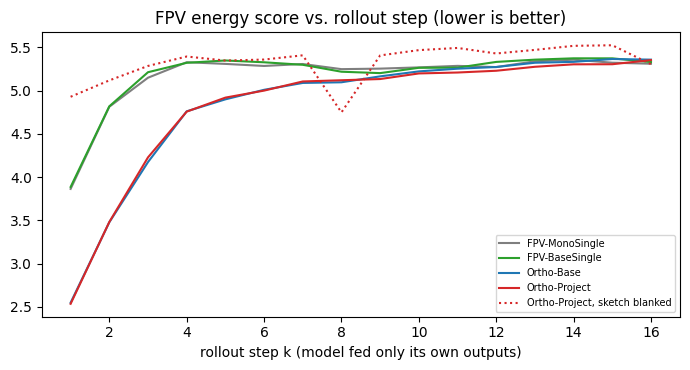

In [8]:
ES_SHOW = (1, 4, 8, 12, 16)
print(f"{'':30s} {'FPV energy score (lower is better)':^39s}")
print(f"{'':30s} " + " ".join(f"{'k=' + str(k):>7s}" for k in ES_SHOW))
for name in es:
    print(f"{name:30s} " + " ".join(f"{es[name][k - 1]:7.3f}" for k in ES_SHOW))

fig, ax = plt.subplots(figsize=(7, 3.8))
styles = {"FPV-MonoSingle": ("tab:gray", "-"), "FPV-BaseSingle": ("tab:green", "-"), "Ortho-Base": ("tab:blue", "-"),
          "Ortho-Project": ("tab:red", "-"), "Ortho-Project, sketch blanked": ("tab:red", ":")}
for name, (color, ls) in styles.items():
    ax.plot(range(1, K + 1), es[name], ls, color=color, label=name)
ax.set_title("FPV energy score vs. rollout step (lower is better)")
ax.set_xlabel("rollout step k (model fed only its own outputs)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 6. How to read this

Numbers are from the run saved in this notebook. Reruns move them by a few hundredths.

**1. Seeing the ortho views makes FPV much better.** At $k=1$, Ortho-Base scores 2.55 against 3.86 for FPV-MonoSingle. FPV alone mixes layout and camera and can't separate them; the ortho views pin down the layout, so FPV then reveals the camera too (context table: 0.187 vs. 0.468).

**2. Predicting ortho views without seeing them doesn't help.** FPV-BaseSingle matches FPV-MonoSingle (3.89 vs. 3.86 at $k=1$, the same curve after that). Its ortho predictions are never fed back, so they add training targets but no information.

**3. Every arm forgets the circuit.** Each new segment is invented on the spot, so by $k\approx 8$–12 every arm flattens out around 5.3. By then, what's in view no longer depends on the start. The ortho advantage is a short-horizon one.

**4. Ortho-Project: the sketch now works, but it can't add information here.**
* **The sketch is right.** Its MSE to FPV$_{t+1}$ is 0.602, against 0.588 for the best linear predictor and 0.879 for predicting nothing.
* **FPV score: a tie with Ortho-Base** (2.535 vs. 2.548 at $k=1$, 5.35 vs. 5.36 at $k=16$, within rerun noise). That's expected in the toy. The DiT already sees Top/Side/Rear and can learn the same linear map, so the sketch gives it a head start but no new information. Any gain in the games would come from that head start (a small LoRA fitting faster), not from information Ortho-Base lacks.
* **Blanking the sketch breaks the model** (4.93 vs. 2.54 at $k=1$). It now relies on the sketch heavily, both as frame 4 and as the noise centre. The blanked run is far off its training distribution, so its later steps (e.g. the dip at $k=8$) don't mean anything.
* **Check in the real run:** `Train/Loss_Sketch` in TensorBoard should fall well below FPV's latent variance. If it stays near or above it, the projector is stuck at its copy-Rear init again; raise `--proj_lr`.